In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import missingno as msno

In [9]:
df = pd.read_csv("creditcard.csv")

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [11]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


# EDA

## cek kualitas data

In [12]:
print(df.duplicated().sum())

1081


In [13]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

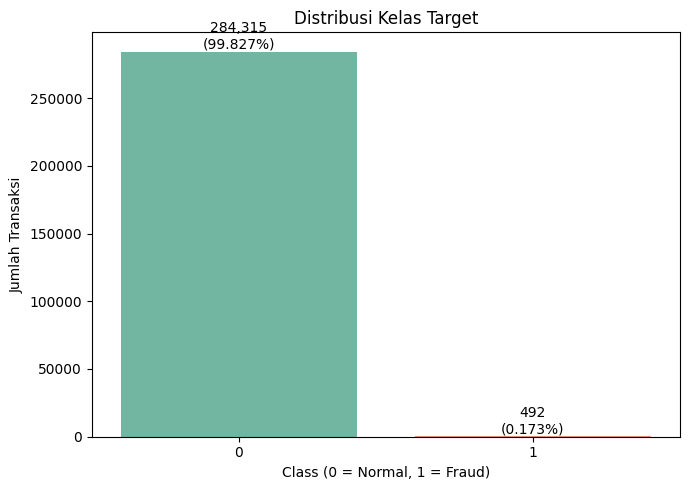

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x='Class', hue='Class', palette='Set2', legend=False)

for p in ax.patches:
    count = int(p.get_height())
    persen = count / len(df) * 100
    ax.annotate(f'{count:,}\n({persen:.3f}%)',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')

plt.title('Distribusi Kelas Target')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Jumlah Transaksi')
plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter

## Split data: training, validation, test
Validation dipakai untuk menentukan bobot blending dan threshold. Test hanya digunakan sekali di akhir. SMOTE hanya pada data training.

In [16]:
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print('Training:', X_train.shape, Counter(y_train))
print('Validation:', X_val.shape, Counter(y_val))
print('Testing:', X_test.shape, Counter(y_test))

Training: (170884, 30) Counter({0: 170589, 1: 295})
Validation: (56961, 30) Counter({0: 56863, 1: 98})
Testing: (56962, 30) Counter({0: 56863, 1: 99})


## Oversampling hanya pada training

In [17]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print('Sebelum SMOTE:', Counter(y_train))
print('Sesudah SMOTE:', Counter(y_train_smote))

Sebelum SMOTE: Counter({0: 170589, 1: 295})
Sesudah SMOTE: Counter({0: 170589, 1: 170589})


## Training LightGBM dan Random Forest

In [18]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_fscore_support, classification_report

lgbm = LGBMClassifier(
    n_estimators=350,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

lgbm.fit(X_train_smote, y_train_smote)
rf.fit(X_train_smote, y_train_smote)

proba_lgbm_val = lgbm.predict_proba(X_val)[:, 1]
proba_rf_val = rf.predict_proba(X_val)[:, 1]

print('PR-AUC LGBM:', round(average_precision_score(y_val, proba_lgbm_val), 5))
print('PR-AUC RF:', round(average_precision_score(y_val, proba_rf_val), 5))

PR-AUC LGBM: 0.81569
PR-AUC RF: 0.79931


## Cari blending weight terbaik menggunakan validation PR-AUC
Bobot LightGBM dicoba dari 0 sampai 1; bobot Random Forest adalah sisanya.

In [19]:
hasil = []
for w in np.arange(0, 1.01, 0.05):
    proba_blend = w * proba_lgbm_val + (1 - w) * proba_rf_val
    ap = average_precision_score(y_val, proba_blend)
    hasil.append([round(w, 2), round(1-w, 2), ap])

hasil_df = pd.DataFrame(hasil, columns=['Bobot LGBM', 'Bobot RF', 'PR-AUC Validation'])
display(hasil_df.sort_values('PR-AUC Validation', ascending=False).head(10))

best_row = hasil_df.loc[hasil_df['PR-AUC Validation'].idxmax()]
best_weight = float(best_row['Bobot LGBM'])
proba_blend_val = best_weight * proba_lgbm_val + (1-best_weight) * proba_rf_val
print('Bobot terpilih - LGBM:', best_weight, 'RF:', round(1-best_weight, 2))

,Bobot LGBM,Bobot RF,PR-AUC Validation
18,0.90,0.10,0.817038
17,0.85,0.15,0.816468
16,0.80,0.20,0.816355
19,0.95,0.05,0.816346
20,1.00,0.00,0.815695
15,0.75,0.25,0.815430
14,0.70,0.30,0.815329
13,0.65,0.35,0.814479
11,0.55,0.45,0.814423
10,0.50,0.50,0.814325


Bobot terpilih - LGBM: 0.9 RF: 0.1


## Optimasi threshold pada validation
SMOTE mengubah prior kelas ketika training, sehingga threshold 0.5 belum tentu ideal. Pilih threshold berdasarkan F1 fraud pada validation.

In [20]:
thresholds = np.arange(0.01, 0.991, 0.01)
f1_scores = []
for t in thresholds:
    pred = (proba_blend_val >= t).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, pred, average='binary', zero_division=0
    )
    f1_scores.append(f1)

best_threshold = float(thresholds[np.argmax(f1_scores)])
print('Threshold terbaik:', round(best_threshold, 3))
print('Validation F1 fraud:', round(max(f1_scores), 5))

Threshold terbaik: 0.75
Validation F1 fraud: 0.83422


## Evaluasi akhir pada test set
Test set tidak digunakan dalam pencarian bobot maupun threshold.

In [21]:
proba_lgbm_test = lgbm.predict_proba(X_test)[:, 1]
proba_rf_test = rf.predict_proba(X_test)[:, 1]
proba_blend_test = best_weight * proba_lgbm_test + (1-best_weight) * proba_rf_test

for nama, proba in [
    ('LightGBM', proba_lgbm_test),
    ('Random Forest', proba_rf_test),
    ('Weighted Blending', proba_blend_test)
]:
    print('\n', nama)
    print('PR-AUC:', round(average_precision_score(y_test, proba), 5))
    print('ROC-AUC:', round(roc_auc_score(y_test, proba), 5))
    pred = (proba >= best_threshold).astype(int)
    print(classification_report(y_test, pred, digits=4, zero_division=0))


 LightGBM
PR-AUC: 0.85444
ROC-AUC: 0.9795
              precision    recall  f1-score   support

           0     0.9998    0.9998    0.9998     56863
           1     0.8947    0.8586    0.8763        99

    accuracy                         0.9996     56962
   macro avg     0.9472    0.9292    0.9380     56962
weighted avg     0.9996    0.9996    0.9996     56962


 Random Forest
PR-AUC: 0.86807
ROC-AUC: 0.97617
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56863
           1     0.9000    0.8182    0.8571        99

    accuracy                         0.9995     56962
   macro avg     0.9498    0.9090    0.9285     56962
weighted avg     0.9995    0.9995    0.9995     56962


 Weighted Blending
PR-AUC: 0.87506
ROC-AUC: 0.97675
              precision    recall  f1-score   support

           0     0.9998    0.9998    0.9998     56863
           1     0.8947    0.8586    0.8763        99

    accuracy                         

**Catatan:** PR-AUC mengukur ranking dan tidak bergantung threshold. Bobot dan threshold yang dipilih pada satu validation split dapat bervariasi; validasi silang bisa memberi estimasi yang lebih stabil.

# Eksperimen lanjutan: SMOTE vs Tanpa SMOTE

Bagian ini **melanjutkan notebook sebelumnya**, tanpa mengulang split data. Kita menggunakan **X_train, X_val, X_test yang sama**. Model SMOTE (`lgbm` dan `rf`) sudah dilatih di bagian sebelumnya; sekarang kita latih pasangan model **tanpa SMOTE** menggunakan hyperparameter yang identik. Kedua pendekatan dibandingkan pada validation set (tanpa oversampling), dan bobot blending serta threshold dipilih **hanya dari validation**. Test digunakan untuk laporan akhir.

In [22]:
# Dua model baru yang dilatih TANPA SMOTE
lgbm_no_smote = LGBMClassifier(
    n_estimators=350,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

rf_no_smote = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

lgbm_no_smote.fit(X_train, y_train)
rf_no_smote.fit(X_train, y_train)

# Model dengan SMOTE: lgbm dan rf dari sel training sebelumnya
pred_val = {
    'LGBM Tanpa SMOTE': lgbm_no_smote.predict_proba(X_val)[:, 1],
    'RF Tanpa SMOTE': rf_no_smote.predict_proba(X_val)[:, 1],
    'LGBM SMOTE': lgbm.predict_proba(X_val)[:, 1],
    'RF SMOTE': rf.predict_proba(X_val)[:, 1]
}

print('Training empat model selesai (dua dari bagian sebelumnya).')

Training empat model selesai (dua dari bagian sebelumnya).


## Cari bobot blending terbaik pada validation

Masing-masing pendekatan (dengan dan tanpa SMOTE) memiliki **bobot sendiri** yang dipilih berdasarkan PR-AUC. Semua evaluasi bobot dilakukan di validation set yang distribusi kelasnya asli.

In [23]:
weight_results = []
for metode in ['Tanpa SMOTE', 'SMOTE']:
    for w in np.arange(0, 1.01, 0.05):
        p = w * pred_val[f'LGBM {metode}'] + (1 - w) * pred_val[f'RF {metode}']
        weight_results.append({
            'Metode': metode,
            'Bobot LGBM': round(float(w), 2),
            'Bobot RF': round(float(1 - w), 2),
            'PR-AUC': average_precision_score(y_val, p)
        })

weight_comparison_df = pd.DataFrame(weight_results)
best_weights = {}
for metode in ['Tanpa SMOTE', 'SMOTE']:
    subset = weight_comparison_df[weight_comparison_df['Metode'] == metode]
    terbaik = subset.loc[subset['PR-AUC'].idxmax()]
    w = float(terbaik['Bobot LGBM'])
    best_weights[metode] = w
    pred_val[f'Blend {metode}'] = w * pred_val[f'LGBM {metode}'] + (1-w) * pred_val[f'RF {metode}']
    print(f"{metode}: bobot LGBM={w:.2f}, RF={1-w:.2f}, PR-AUC={terbaik['PR-AUC']:.5f}")

display(weight_comparison_df.sort_values('PR-AUC', ascending=False).head(10))

Tanpa SMOTE: bobot LGBM=0.00, RF=1.00, PR-AUC=0.80260
SMOTE: bobot LGBM=0.90, RF=0.10, PR-AUC=0.81704


,Metode,Bobot LGBM,Bobot RF,PR-AUC
39,SMOTE,0.90,0.10,0.817038
38,SMOTE,0.85,0.15,0.816468
37,SMOTE,0.80,0.20,0.816355
40,SMOTE,0.95,0.05,0.816346
41,SMOTE,1.00,0.00,0.815695
36,SMOTE,0.75,0.25,0.815430
35,SMOTE,0.70,0.30,0.815329
34,SMOTE,0.65,0.35,0.814479
32,SMOTE,0.55,0.45,0.814423
31,SMOTE,0.50,0.50,0.814325


## Evaluasi validation dan visualisasi

PR-AUC paling penting untuk membandingkan ranking probabilitas pada kelas fraud yang langka. Precision, Recall, dan F1 di tabel pertama menggunakan threshold tetap **0.5** agar semua metode dibandingkan pada aturan keputusan yang sama.

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1
5,Blend SMOTE,0.8170,0.9832,0.7959,0.7959,0.7959
2,LGBM SMOTE,0.8157,0.9819,0.8041,0.7959,0.8000
4,Blend Tanpa SMOTE,0.8026,0.9784,0.9359,0.7449,0.8295
1,RF Tanpa SMOTE,0.8026,0.9784,0.9359,0.7449,0.8295
3,RF SMOTE,0.7993,0.9830,0.7333,0.7857,0.7586
0,LGBM Tanpa SMOTE,0.3140,0.8002,0.2198,0.6122,0.3235


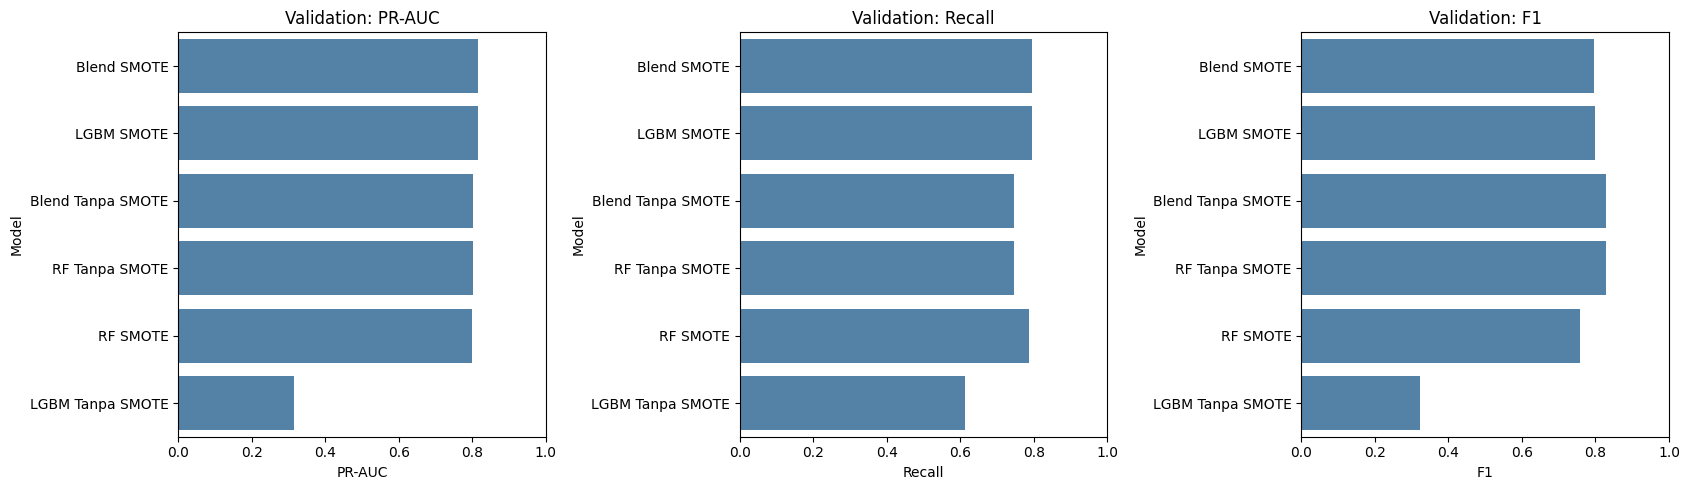

In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score

rows = []
for nama, prob in pred_val.items():
    pred = (prob >= 0.5).astype(int)
    rows.append({
        'Model': nama,
        'PR-AUC': average_precision_score(y_val, prob),
        'ROC-AUC': roc_auc_score(y_val, prob),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Recall': recall_score(y_val, pred, zero_division=0),
        'F1': f1_score(y_val, pred, zero_division=0)
    })

validation_results_df = pd.DataFrame(rows).sort_values('PR-AUC', ascending=False)
display(validation_results_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metrik in zip(axes, ['PR-AUC', 'Recall', 'F1']):
    sns.barplot(data=validation_results_df, x=metrik, y='Model', color='steelblue', ax=ax)
    ax.set_title(f'Validation: {metrik}')
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

## Threshold terbaik berdasarkan validation F1

Threshold dioptimasi **secara terpisah untuk masing-masing model**, karena SMOTE bisa mengubah kalibrasi probabilitas. Nilai threshold terpilih ini dibekukan sebelum menghitung metrik pada test.

In [25]:
best_thresholds = {}
threshold_rows = []
for nama, prob in pred_val.items():
    calon_threshold = np.arange(0.01, 1.0, 0.01)
    skor_f1 = [f1_score(y_val, (prob >= t).astype(int), zero_division=0) for t in calon_threshold]
    idx = int(np.argmax(skor_f1))
    best_thresholds[nama] = float(calon_threshold[idx])
    threshold_rows.append({
        'Model': nama,
        'Threshold validation': best_thresholds[nama],
        'F1 validation': skor_f1[idx]
    })

display(pd.DataFrame(threshold_rows).sort_values('F1 validation', ascending=False).round(4))

,Model,Threshold validation,F1 validation
5,Blend SMOTE,0.75,0.8342
1,RF Tanpa SMOTE,0.36,0.8324
4,Blend Tanpa SMOTE,0.36,0.8324
2,LGBM SMOTE,0.89,0.8306
3,RF SMOTE,0.85,0.8090
0,LGBM Tanpa SMOTE,0.99,0.3762


## Evaluasi akhir pada test set (tanpa SMOTE)

Bobot dan threshold sudah dipilih berdasarkan validation. Test tidak digunakan untuk memilih pemenang atau mengoptimalkan konfigurasi lagi. Jika data test sudah pernah diperiksa pada bagian sebelumnya, hasil ini tetap berguna sebagai perbandingan, tetapi jangan melakukan tuning lanjutan berdasarkan test.

,Model,PR-AUC,ROC-AUC,Threshold,Precision,Recall,F1
5,Blend SMOTE,0.8751,0.9767,0.75,0.8947,0.8586,0.8763
1,RF Tanpa SMOTE,0.8745,0.9734,0.36,0.9121,0.8384,0.8737
4,Blend Tanpa SMOTE,0.8745,0.9734,0.36,0.9121,0.8384,0.8737
3,RF SMOTE,0.8681,0.9762,0.85,0.9070,0.7879,0.8432
2,LGBM SMOTE,0.8544,0.9795,0.89,0.9032,0.8485,0.8750
0,LGBM Tanpa SMOTE,0.4097,0.7911,0.99,0.3568,0.6667,0.4648


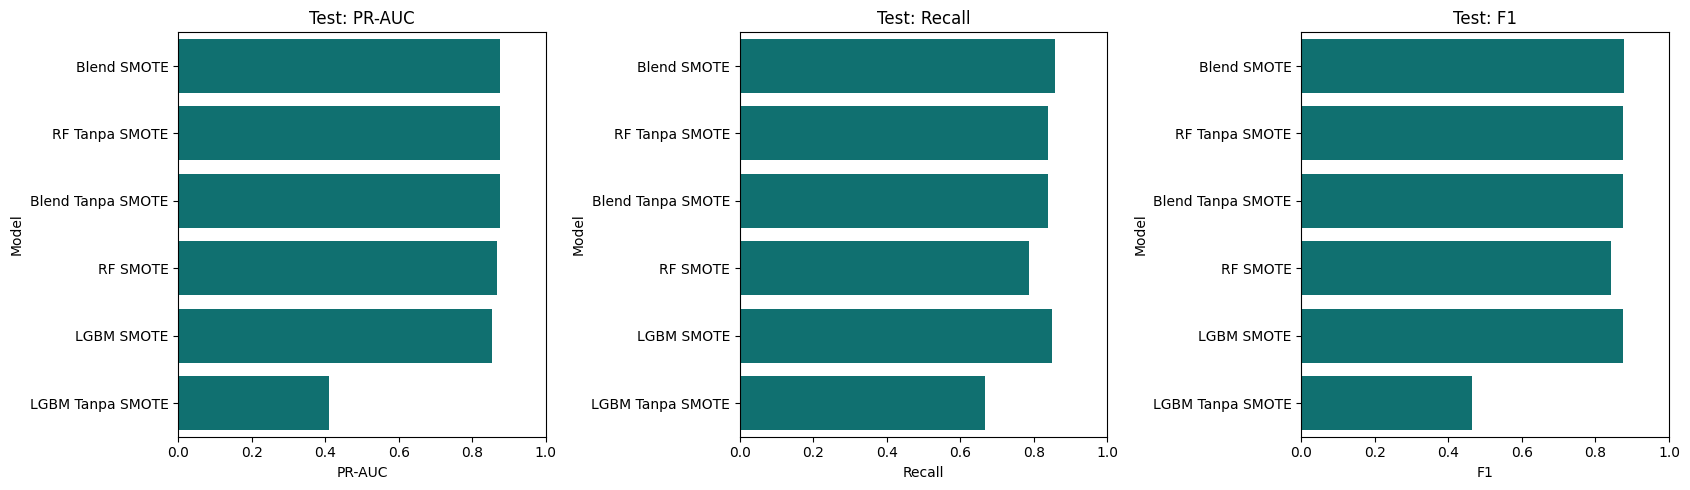

In [26]:
pred_test = {
    'LGBM Tanpa SMOTE': lgbm_no_smote.predict_proba(X_test)[:, 1],
    'RF Tanpa SMOTE': rf_no_smote.predict_proba(X_test)[:, 1],
    'LGBM SMOTE': lgbm.predict_proba(X_test)[:, 1],
    'RF SMOTE': rf.predict_proba(X_test)[:, 1]
}
for metode in ['Tanpa SMOTE', 'SMOTE']:
    w = best_weights[metode]
    pred_test[f'Blend {metode}'] = w * pred_test[f'LGBM {metode}'] + (1-w) * pred_test[f'RF {metode}']

rows_test = []
for nama, prob in pred_test.items():
    pred = (prob >= best_thresholds[nama]).astype(int)
    rows_test.append({
        'Model': nama,
        'PR-AUC': average_precision_score(y_test, prob),
        'ROC-AUC': roc_auc_score(y_test, prob),
        'Threshold': best_thresholds[nama],
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0)
    })

test_results_df = pd.DataFrame(rows_test).sort_values('PR-AUC', ascending=False)
display(test_results_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metrik in zip(axes, ['PR-AUC', 'Recall', 'F1']):
    sns.barplot(data=test_results_df, x=metrik, y='Model', color='teal', ax=ax)
    ax.set_title(f'Test: {metrik}')
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()